In [71]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [72]:
# Create a Model Class that inherits nn.Module
class Model(nn.Module):
    def __init__(self, in_features=4, h1=8, h2=9, out_features=3, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.fc1 = nn.Linear(in_features, h1)
        self.fc2 = nn.Linear(h1, h2)
        self.out = nn.Linear(h2, out_features)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.out(x)

        return x

In [73]:
torch.manual_seed(41)
model = Model()

In [74]:
import pandas as pd

df = pd.read_csv('Iris.csv').drop('Id', axis=1)
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [75]:
df["Species"] = df["Species"].replace({'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2})
df['Species'].value_counts()

/tmp/ipykernel_30016/1650904440.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Species"] = df["Species"].replace({'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2})


Species
0    50
1    50
2    50
Name: count, dtype: int64

In [76]:
X = df.drop('Species', axis=1)
y = df["Species"]

In [77]:
from sklearn.model_selection import train_test_split

In [78]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=41)

In [79]:
X_train = torch.FloatTensor(X_train.to_numpy())
X_test = torch.FloatTensor(X_test.to_numpy())


In [80]:
y_train = torch.LongTensor(y_train.to_numpy())
y_test = torch.LongTensor(y_test.to_numpy())

In [86]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


In [87]:
model.parameters

<bound method Module.parameters of Model(
  (fc1): Linear(in_features=4, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)>

In [88]:
epochs = 1000
losses = []
for i in range(epochs):
    y_pred = model.forward(X_train)
    loss = criterion(y_pred, y_train)
    losses.append(loss.detach().numpy())

    if i % 10 == 0:
        print("Iteration {} \nLoss: {}".format(i, loss.detach().numpy()))

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Iteration 0 
Loss: 0.0007338413852266967
Iteration 10 
Loss: 0.0007479449268430471
Iteration 20 
Loss: 0.0007370083476416767
Iteration 30 
Loss: 0.0007213859353214502
Iteration 40 
Loss: 0.0007089797290973365
Iteration 50 
Loss: 0.0007028331747278571
Iteration 60 
Loss: 0.0006962647312320769
Iteration 70 
Loss: 0.0006897948915138841
Iteration 80 
Loss: 0.0006830912898294628
Iteration 90 
Loss: 0.0006763272685930133
Iteration 100 
Loss: 0.000669446773827076
Iteration 110 
Loss: 0.0006624440429732203
Iteration 120 
Loss: 0.0006553336861543357
Iteration 130 
Loss: 0.0006481482996605337
Iteration 140 
Loss: 0.0006408860208466649
Iteration 150 
Loss: 0.0006335809011943638
Iteration 160 
Loss: 0.0006262296228669584
Iteration 170 
Loss: 0.0006188461557030678
Iteration 180 
Loss: 0.0006114324205555022
Iteration 190 
Loss: 0.0006040045991539955
Iteration 200 
Loss: 0.0005966079770587385
Iteration 210 
Loss: 0.0005891822511330247
Iteration 220 
Loss: 0.0005817878991365433
Iteration 230 
Loss: 0.

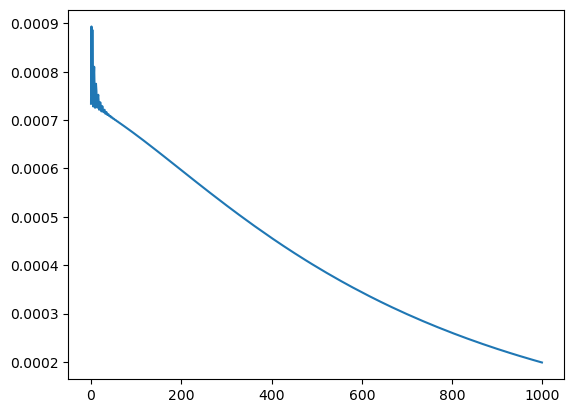

In [89]:
import matplotlib.pyplot as plt
plt.plot(losses)